# Final Model Report

## Drone Delivery On-Time Prediction

The goal is to answer three practical questions:

1. **How well does the model perform?**
2. **Which operational factors appear to drive delivery delays?**
3. **How could this model support delivery planning decisions?**


## 1. Imports and paths

This notebook doesn't tune anything — it reconstructs the already-selected pipeline architecture via `build_pipeline`, then sets its hyperparameters to the winning values loaded from `02_Model_Training.ipynb`'s output. Tuning only happens once, in notebook 02.


In [1]:
from pathlib import Path
import sys
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_loading import load_drone_delivery_data
from src.modeling import build_pipeline

DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "figures" / "final_report"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"
SUBMISSIONS_DIR = PROJECT_ROOT / "outputs" / "submissions"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

for path in [FIGURES_DIR, MODELS_DIR, SUBMISSIONS_DIR, TABLES_DIR]:  # METRICS_DIR is read-only here, created by 02_Model_Training.ipynb
    path.mkdir(parents=True, exist_ok=True)


## 2. Executive summary

The final model selected from the model comparison stage was **Logistic Regression**.

This model was selected primarily for its **interpretability** (direct coefficients / odds ratios, shown below). Its validation ROC-AUC was comparable to a HistGradientBoosting model tried during model selection — the two models' 95% confidence intervals overlap — so predictive performance was not the deciding factor on its own.

**Validation performance**

| Metric | Result |
|---|---:|
| ROC-AUC | **0.911 [0.906, 0.917]** |
| PR-AUC | **0.944 [0.939, 0.949]** |
| F1-score | **0.836 [0.829, 0.844]** |
| Accuracy | **0.813 [0.805, 0.821]** |

**Business interpretation**

The model can be used as a decision-support tool to estimate whether a drone delivery is likely to arrive on time before dispatch. The most interpretable operational drivers are related to route complexity, payload, drone model, wind and altitude changes.

`landing_zone` is retained in the predictive model because it may capture location-specific patterns, but individual landing-zone labels are not used as the main business explanation.


## 3. Load data

Reloads from the same raw files as notebook 02 rather than reusing its in-memory data, so this notebook stays self-contained and can be run independently — e.g. re-running just the final report after re-training — from a fresh kernel.


In [2]:
train, test, sample_submission = load_drone_delivery_data(DATA_DIR)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

train.head()


Loading: C:\Users\voula\Desktop\drone\data\raw\train.csv
Loading: C:\Users\voula\Desktop\drone\data\raw\test.csv
Loading: C:\Users\voula\Desktop\drone\data\raw\sample_submission.csv
Train shape: (40000, 11)
Test shape: (10000, 10)
Sample submission shape: (10000, 2)


,Id,distance_km,payload_kg,drone_model,slot_15min,wind_token,route_turns,alt_profile,landing_zone,operator_tag,on_time
0,1662,3.498,2.676,B,75,S-0/4,UUUUURLUD,0-0-0-0-1-1-1-1-1,LZ-146,safe,1
1,4591,2.209,1.480,B,30,SE-3/5,LLLULLLULLLDLUUULUUU,1-1-1-2-2-2-2-3-2-1-2-3-2-1-1-2-3-2-3-3,LZ-278,balanced,0
2,38756,1.876,0.267,A,26,N-3/5,RRURDDDRDDDRRURDRDRD,0-0-0-1-1-1-1-0-1-1-2-2-2-3-3-3-3-3-3-3,LZ-108,balanced,0
3,31027,1.496,0.510,A,9,E-10/18,LLDDDDLDDRDDRDDDDDDD,0-1-0-0-0-1-2-2-2-2-2-2-3-3-3-3-3-3-3-3,LZ-243,balanced,0
4,1642,2.041,0.240,B,52,SW-11/19,DRRDRRRURDRRDDLDDLDR,1-1-1-1-1-1-2-2-2-2-2-2-2-1-1-1-2-2-2-2,LZ-030,safe,0


## 4. Final selected model

The selected model is refitted on the full labelled training dataset before generating final predictions.

This is standard practice after model selection because it allows the final model to learn from all available labelled examples. Notebook 02's pipeline was only fit on the 80% training split, holding back 20% for validation — that held-back 20% was essential for getting an honest performance estimate, but once the model is chosen there's no reason to keep denying it that data. Refitting the same architecture and hyperparameters on the full `train` set gives the final deployed model the maximum amount of information to learn from.


In [3]:
TARGET = "on_time"
ID_COL = "Id"

# Load the winning model + hyperparameters from 02_Model_Training.ipynb instead of
# hardcoding them here, so this notebook always reflects whatever that notebook last
# selected rather than a value someone has to remember to update by hand.
summary_path = METRICS_DIR / "best_model_summary.json"
if not summary_path.exists():
    raise FileNotFoundError(
        f"{summary_path} not found. Run 02_Model_Training.ipynb first "
        "(with QUICK_MODE = False for a real run) so it can save the winning "
        "model name and hyperparameters."
    )

with open(summary_path, "r", encoding="utf-8") as f:
    best_model_summary = json.load(f)

best_model_name = best_model_summary["best_model_name"]
best_params = best_model_summary["best_params"]

if best_model_summary.get("quick_mode"):
    print(
        "WARNING: best_model_summary.json was generated with QUICK_MODE = True in "
        "02_Model_Training.ipynb. These are debug-run results, not the real numbers. "
        "Re-run notebook 02 with QUICK_MODE = False before finalizing this report."
    )

print("Loaded best model:", best_model_name)
print("Loaded best params:", best_params)

X_full = train.drop(columns=[TARGET])
y_full = train[TARGET]

final_pipeline = build_pipeline(best_model_name)
final_pipeline.set_params(**best_params)

final_pipeline.fit(X_full, y_full)

print("Final model fitted on full training data.")


Loaded best model: logistic_regression
Loaded best params: {'classifier__C': 0.4205156450913872, 'classifier__penalty': 'l2'}


c:\Users\voula\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Final model fitted on full training data.


## 5. Extract model drivers

For Logistic Regression, coefficients indicate whether a feature increases or decreases the predicted probability of an on-time delivery.

However, this notebook avoids presenting individual `landing_zone` coefficients as main findings because there are many landing zones and each one represents a specific location label.

Instead, the main interpretation focuses on broader operational features. This is the direct payoff of choosing an interpretable model in notebook 02 — each coefficient has a precise, explainable meaning (via its odds ratio) that a manager can act on, unlike a Random Forest or HistGradientBoosting model where "importance" is harder to translate into a clear direction of effect.


In [4]:
# Extract transformed feature names and coefficients
preprocessor = final_pipeline.named_steps["preprocessing"]
classifier = final_pipeline.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients),
    "odds_ratio": np.exp(coefficients),
})

coef_df["is_landing_zone"] = coef_df["feature"].str.startswith("landing_zone_")

def feature_group(feature):
    if feature.startswith("landing_zone_"):
        return "Landing zone"
    if feature in ["route_length", "direction_changes"]:
        return "Route complexity"
    if feature == "payload_kg":
        return "Payload"
    if feature == "distance_km":
        return "Distance"
    if feature in ["wind_avg", "wind_gust"] or feature.startswith("wind_direction_"):
        return "Wind"
    if feature in ["mean_altitude", "altitude_changes"]:
        return "Altitude profile"
    if feature.startswith("drone_model_"):
        return "Drone model"
    if feature.startswith("operator_tag_"):
        return "Operator strategy"
    if feature == "slot_15min":
        return "Time of day"
    return "Other"

coef_df["feature_group"] = coef_df["feature"].apply(feature_group)

non_lz_coef_df = coef_df[~coef_df["is_landing_zone"]].copy()
non_lz_coef_df = non_lz_coef_df.sort_values("abs_coefficient", ascending=False)

display(non_lz_coef_df.head(20))

coef_df.to_csv(TABLES_DIR / "all_model_coefficients.csv", index=False)
non_lz_coef_df.to_csv(TABLES_DIR / "interpretable_coefficients_excluding_landing_zone.csv", index=False)


,feature,coefficient,abs_coefficient,odds_ratio,is_landing_zone,feature_group
5,route_length,-2.154887,2.154887,0.115916,False,Route complexity
1,payload_kg,-1.314000,1.314000,0.268743,False,Payload
10,drone_model_B,1.090768,1.090768,2.976560,False,Drone model
6,direction_changes,-1.021011,1.021011,0.360231,False,Route complexity
312,operator_tag_aggressive,0.844621,0.844621,2.327097,False,Operator strategy
4,wind_gust,-0.626596,0.626596,0.534408,False,Wind
314,operator_tag_safe,-0.527291,0.527291,0.590202,False,Operator strategy
8,altitude_changes,-0.329765,0.329765,0.719093,False,Altitude profile
7,mean_altitude,-0.315230,0.315230,0.729621,False,Altitude profile
313,operator_tag_balanced,0.294710,0.294710,1.342737,False,Operator strategy


## 6. Main operational drivers

The plot below shows the strongest positive and negative non-location drivers.

- **Positive coefficients** increase the predicted probability of arriving on time.
- **Negative coefficients** decrease the predicted probability of arriving on time.

Landing zone is not dropped from the model itself — it's set aside from this particular chart so the plot stays focused on levers the business can actually act on.


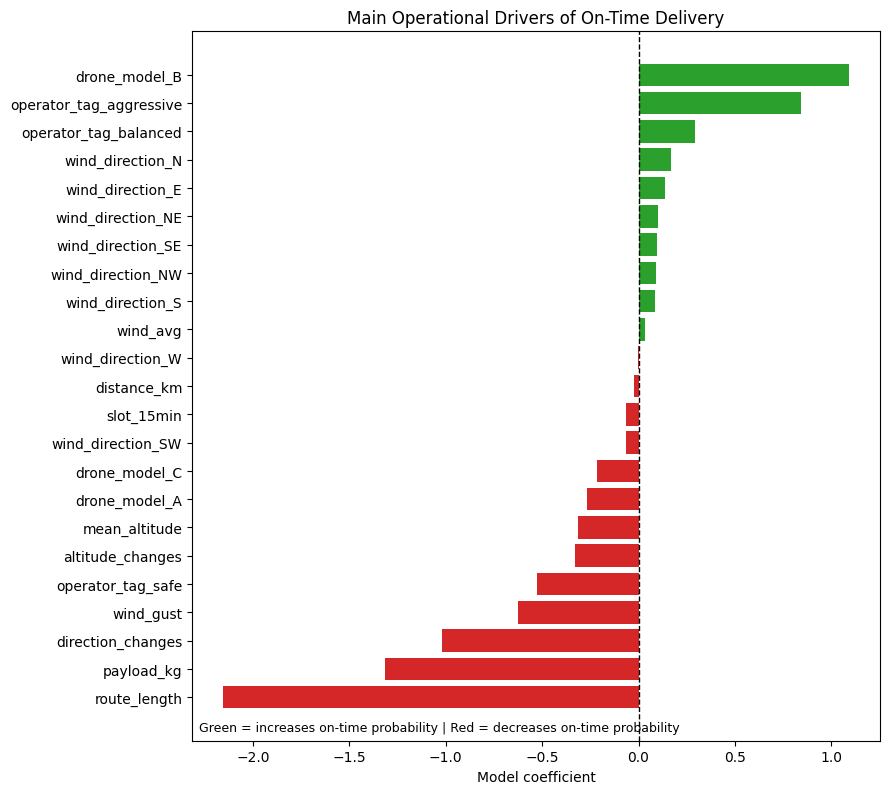

In [5]:
top_n = 12

top_positive = non_lz_coef_df.sort_values("coefficient", ascending=False).head(top_n)
top_negative = non_lz_coef_df.sort_values("coefficient", ascending=True).head(top_n)

plot_df = pd.concat([top_negative, top_positive]).drop_duplicates("feature")
plot_df = plot_df.sort_values("coefficient")

colors = np.where(plot_df["coefficient"] >= 0, "tab:green", "tab:red")

fig, ax = plt.subplots(figsize=(9, max(6, 0.35 * len(plot_df))))
ax.barh(plot_df["feature"], plot_df["coefficient"], color=colors)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Model coefficient")
ax.set_title("Main Operational Drivers of On-Time Delivery")
ax.text(
    0.01,
    0.01,
    "Green = increases on-time probability | Red = decreases on-time probability",
    transform=ax.transAxes,
    fontsize=9,
    va="bottom",
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "main_operational_drivers.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation

The model suggests that delivery performance is mainly affected by operational complexity rather than by one single factor.

The most useful interpretation is:

- **Route complexity matters:** longer or more complex routes are strongly associated with delivery timing.
- **Payload matters:** heavier deliveries are harder to complete on time.
- **Drone model matters:** model choice appears to influence delivery reliability.
- **Operator strategy matters:** the operating mode affects the probability of on-time completion.
- **Weather and altitude profile matter:** wind and altitude changes contribute to delivery difficulty.

Although `landing_zone` is included in the model, individual landing-zone labels should be interpreted as **location-specific effects**, not as universal business rules.


> **Note on operator strategy.** `aggressive`-tagged missions have the highest on-time rate and `safe`-tagged missions the lowest, and the model's coefficients reproduce this direction. This was checked against a route-assignment confound (whether aggressive operators are simply dispatched on shorter/lighter/simpler missions) in the EDA notebook: mission characteristics (distance, payload, route complexity, altitude profile) are essentially identical across the three operator groups, so the effect is not explained by differences in the missions assigned to each group.

## 7. Feature-family view

Instead of looking at individual dummy variables, features can be grouped into broader business categories.

This view is more suitable because it summarizes model behaviour in operational terms. Groups have very different numbers of one-hot encoded columns (e.g. `Landing zone` has ~300, `Wind` has only a handful), so summing coefficients within a group would make large groups look artificially important purely because they have more columns. Mean and max absolute coefficient are comparable across groups regardless of how many columns each one contains.


,feature_group,n_features,mean_abs_coefficient,max_abs_coefficient
0,Route complexity,2,1.587949,2.154887
1,Payload,1,1.314000,1.314000
2,Operator strategy,3,0.555541,0.844621
3,Drone model,3,0.523165,1.090768
4,Landing zone,300,0.420831,1.397999
5,Altitude profile,2,0.322497,0.329765
6,Wind,10,0.141153,0.626596
7,Time of day,1,0.064293,0.064293
8,Distance,1,0.023808,0.023808


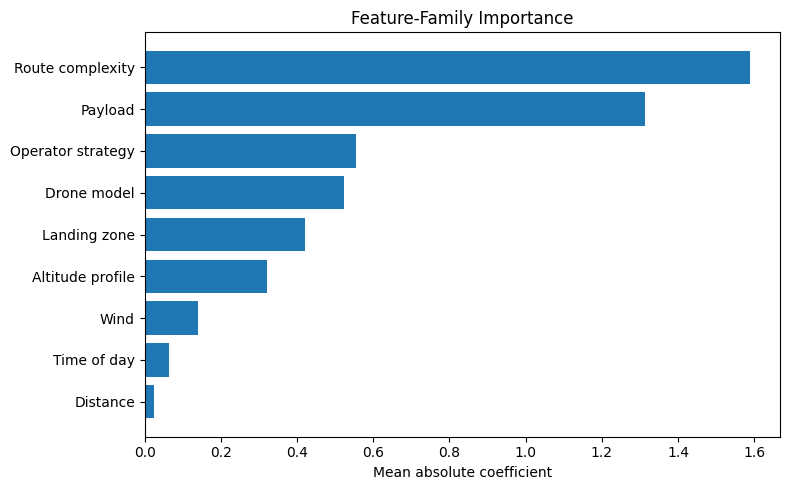

In [6]:
grouped_df = (
    coef_df
    .groupby("feature_group")
    .agg(
        n_features=("feature", "count"),
        mean_abs_coefficient=("abs_coefficient", "mean"),
        max_abs_coefficient=("abs_coefficient", "max"),
    )
    .sort_values("mean_abs_coefficient", ascending=False)
    .reset_index()
)

display(grouped_df)

grouped_df.to_csv(TABLES_DIR / "feature_family_importance.csv", index=False)

plot_grouped = grouped_df.sort_values("mean_abs_coefficient", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_grouped["feature_group"], plot_grouped["mean_abs_coefficient"])
ax.set_xlabel("Mean absolute coefficient")
ax.set_title("Feature-Family Importance")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_family_importance.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretation of Landing Zones

The model includes `landing_zone` because different destinations may have different delivery characteristics that improve prediction accuracy.

However, these effects are location-specific and are not considered general operational drivers.

Instead, the main factors that can be acted upon are route complexity, payload, drone selection, operator strategy, and weather conditions.


## 8. Practical decision-support use case

A logistics team could use the model before dispatch to estimate the probability of on-time delivery.

For example:

| Predicted probability | Suggested action |
|---:|---|
| > 0.80 | Approve delivery normally |
| 0.50–0.80 | Review operational risk factors |
| < 0.50 | Consider mitigation, different drone, different timing, or alternative delivery method |

This converts the model from a pure prediction exercise into a practical decision-support tool. A bare 0/1 prediction hides how confident the model is — a mission at 51% and one at 95% would both just say "on time," but they call for very different operational responses. Turning the raw probability into a three-tier action table is what makes the model something a dispatcher can use day-to-day.


## 9. Save final fitted pipeline

`final_pipeline` bundles feature engineering, preprocessing, and the classifier into one object (see `src/modeling.py`'s `build_pipeline`). Saving the whole pipeline means anyone loading this `.pkl` later can call `.predict_proba()` directly on raw new data, without needing to remember or re-implement the preprocessing steps separately.


In [7]:
model_path = MODELS_DIR / f"final_{best_model_name}_pipeline.pkl"

joblib.dump(final_pipeline, model_path)

print("Saved final pipeline to:")
print(model_path)


Saved final pipeline to:
C:\Users\voula\Desktop\drone\outputs\models\final_logistic_regression_pipeline.pkl


## 10. Example production inference

After deployment, the saved pipeline can be loaded by an application and used to estimate the probability that a **single new delivery request** will arrive on time.

The example below demonstrates a typical production prediction using one delivery request from the available data.

In [8]:
example_delivery = test.iloc[[0]].copy()

predicted_probability = final_pipeline.predict_proba(example_delivery)[0, 1]

print(f"Predicted probability of on-time delivery: {predicted_probability:.3f}")

prediction = pd.DataFrame({
    "Predicted probability": [predicted_probability]
})

display(prediction)


Predicted probability of on-time delivery: 0.720


,Predicted probability
0,0.719983


## 11. Save final metadata

In [9]:
metadata = {
    "model_name": best_model_name,
    "best_params": best_params,
    "training_rows": int(train.shape[0]),
    "saved_model_path": str(model_path),
    "target": TARGET,
    "deployment_ready": True,
}

metadata_path = MODELS_DIR / "final_model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Saved metadata to:")
print(metadata_path)


Saved metadata to:
C:\Users\voula\Desktop\drone\outputs\models\final_model_metadata.json


## 12. Final conclusion

The final Logistic Regression model provides a strong and interpretable baseline for predicting on-time drone deliveries.

The main value of the model is not only prediction accuracy, but its ability to support operational decisions before dispatch. By identifying higher-risk missions, the model could help a logistics team prioritize review, adjust routes, select different drones or apply mitigation strategies before delays occur.
